# Personal Finance Analysis and Expense Forecasting with Python

Analysis of six months of personal income and expense data: monthly cash flow, spending by category and account, an interactive dashboard, and a 3-month expense forecast compared across three methods (moving average, linear trend, exponential smoothing) using backtested MAE.

**Dataset:** [Data Finance 6 Bulan](https://www.kaggle.com/datasets/ugisugiman/data-finance), amounts in Indonesian Rupiah (Rp).

In [1]:
import pandas as pd

df = pd.read_csv("dataset/Data_Finance_6_Bulan.csv")
df

,Date,Title,Amount,Type,Category,Account
0,2025-07-01,Parkir,15907.28,EXPENSE,Tagihan,Gopay
1,2025-07-01,Iuran Bulanan,12793.08,EXPENSE,Tagihan,BCA
2,2025-07-01,Lain-lain,695.24,EXPENSE,Uncategorized,Gopay
3,2025-07-01,Streaming,13464.10,EXPENSE,Hiburan,Dompet Tunai
4,2025-07-01,Warung Nasi,17475.95,EXPENSE,Makan & Minum,Dompet Tunai
...,...,...,...,...,...,...
1195,2025-12-31,Makan Malam,16278.67,EXPENSE,Makan & Minum,Dompet Tunai
1196,2025-12-31,Internet,10184.36,EXPENSE,Tagihan,Gopay
1197,2025-12-31,Belanja Mingguan,12712.85,EXPENSE,Belanja,Gopay
1198,2025-12-31,Makan Siang,15538.97,EXPENSE,Makan & Minum,Gopay


In [2]:
# check data types & missing value
print(f"""{df.dtypes}

{df.isnull().sum()}""")

Date            str
Title           str
Amount      float64
Type            str
Category        str
Account         str
dtype: object

Date        0
Title       0
Amount      0
Type        0
Category    0
Account     0
dtype: int64


In [3]:
# convert data type into datetime
df['Date'] = pd.to_datetime(df['Date'])

print(df.dtypes)

Date        datetime64[us]
Title                  str
Amount             float64
Type                   str
Category               str
Account                str
dtype: object


In [4]:
# monthly expenses and income

df['Month'] = df['Date'].dt.to_period('M')
in_out_month = df.groupby(['Month', 'Type'])['Amount'].sum().unstack()

print(in_out_month)

Type       EXPENSE     INCOME
Month                        
2025-07  1783618.0  2823645.0
2025-08  1711084.0  2805109.0
2025-09  1883022.0  2512525.0
2025-10  1285211.0  2014120.0
2025-11  1190022.0  2428896.0
2025-12  1535932.0  2150783.0


In [5]:
# sort by category with the highest spending

exp_category = (df[df['Type'] == 'EXPENSE']
               .groupby('Category')['Amount'].sum()
               .sort_values(ascending=False))

print(exp_category)

Category
Uncategorized    2113972.86
Makan & Minum    2063287.96
Tagihan          1856494.83
Hiburan          1723711.41
Belanja          1631421.94
Name: Amount, dtype: float64


In [6]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets

df['Month'] = df['Month'].astype(str)

def dashboard(month='All', acc='All'):
    d = df.copy()
    if month != 'All':
        d = d[d['Month'] == month]
    if acc != 'All':
        d = d[d['Account'] == acc]

    income = d.loc[d['Type'] == 'INCOME', 'Amount'].sum()
    expense = d.loc[d['Type'] == 'EXPENSE', 'Amount'].sum()
    net = income - expense
    saving_rate = net / income * 100 if income else 0

    cf = (d.groupby(['Month', 'Type'])['Amount'].sum()
            .unstack(fill_value=0)
            .reindex(columns=['INCOME', 'EXPENSE'], fill_value=0))
    exp_d = d[d['Type'] == 'EXPENSE']
    cat = exp_d.groupby('Category')['Amount'].sum().sort_values(ascending=False)
    acc_exp = exp_d.groupby('Account')['Amount'].sum()

    fig = make_subplots(
        rows=2, cols=2,
        specs=[[{}, {}], [{'type': 'domain'}, {}]],
        subplot_titles=('Cash Flow', 'Net (Income - Expense)',
                        'Composition of Expenditures', 'Expenses per Account')
    )

    fig.add_bar(x=cf.index, y=cf['INCOME'], name='INCOME',
                marker_color='#2ca02c', row=1, col=1)
    fig.add_bar(x=cf.index, y=cf['EXPENSE'], name='EXPENSE',
                marker_color='#d62728', row=1, col=1)
    fig.add_scatter(x=cf.index, y=cf['INCOME'] - cf['EXPENSE'],
                    mode='lines+markers', name='Net', row=1, col=2)
    fig.add_pie(labels=cat.index, values=cat.values, hole=0.4,
                name='', row=2, col=1)
    fig.add_bar(x=acc_exp.index, y=acc_exp.values, name='Per account',
                showlegend=False, row=2, col=2)

    fig.update_layout(
        height=750, barmode='group',
        title_text=(f"Income {income:,.0f}  |  Expense {expense:,.0f}  |  "
                    f"Net {net:,.0f}  |  Saving rate {saving_rate:.1f}%"))
    return fig

def graph(month, acc):
    dashboard(month, acc).show()

widgets.interact(
    graph,
    month=['All'] + sorted(df['Month'].unique()),
    acc=['All'] + sorted(df['Account'].unique()))

interactive(children=(Dropdown(description='month', options=('All', '2025-07', '2025-08', '2025-09', '2025-10'…

<function __main__.graph(month, acc)>

In [7]:
import numpy as np

exp_month = (df[df['Type'] == 'EXPENSE'].groupby('Month')['Amount'].sum())
exp_month.index = exp_month.index.astype(str)

y = exp_month.values
x = np.arange(len(y))

# method 1 Moving average
ma3 = y[-3:].mean()

# method 2 linear trend
slope, intercept = np.polyfit(x, y, 1)
n_ahead = 3
future_x = np.arange(len(y), len(y) + n_ahead)
linear_pred = slope * future_x + intercept

# method 3 exp. smoothing
alpha = 0.5
s = y[0]
for v in y[1:]:
    s = alpha * v + (1 - alpha) * s
ses = s

print(f'Moving average 3 Months : {ma3:.0f}')
print(f'linear trend (3 Months) : {linear_pred.round(0)}')
print(f'Exp. Smoothing : {ses:.0f}')

Moving average 3 Months : 1337055
linear trend (3 Months) : [1224872. 1127746. 1030619.]
Exp. Smoothing : 1453021


In [8]:
# calculate MAE every method

def f_ma3(train):
    return train[-3:].mean()

def f_linear(train):
    x = np.arange(len(train))
    slope, intercept = np.polyfit(x, train, 1)
    return slope * len(train) + intercept

def f_ses(train, alpha=0.5):
    s = train[0]
    for v in train[1:]:
        s = alpha * v + (1 - alpha) * s
    return s

methods = {'Moving average 3 Months': f_ma3,
         'Linear Trend (3 Months)': f_linear,
         'Exp. Smoothing': f_ses}

for name, fn in methods.items():
    errors = []
    for t in range(3, len(y)):
        pred = fn(y[:t])
        errors.append(abs(y[t] - pred))
    print(f"{name:22s} MAE: {np.mean(errors):.0f}")

Moving average 3 Months MAE: 342320
Linear Trend (3 Months) MAE: 400306
Exp. Smoothing         MAE: 351991


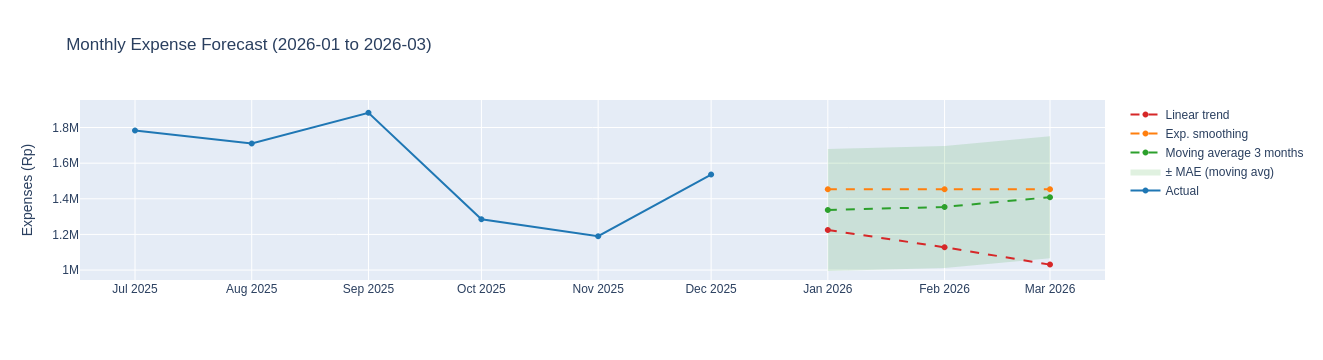

In [9]:
import plotly.graph_objects as go

# MAE from backtesting (moving average), same method as the MAE cell above
errors_ma = [abs(y[t] - f_ma3(y[:t])) for t in range(3, len(y))]
mae = np.mean(errors_ma)

# next months, continuing from the last month in the data
next_months = pd.period_range(pd.Period(exp_month.index[-1], freq='M') + 1,
                              periods=n_ahead, freq='M').astype(str)

# recursive moving average
hist = list(y)
ma_pred = []
for _ in range(n_ahead):
    p = np.mean(hist[-3:])
    ma_pred.append(p)
    hist.append(p)

# exp. smoothing (flat forecast)
ses_pred = [f_ses(y)] * n_ahead

fig = go.Figure()

# actual data
fig.add_scatter(x=exp_month.index, y=y, mode='lines+markers', name='Actual',
                line=dict(color='#1f77b4'))

# uncertainty band for moving average (± MAE)
fig.add_scatter(x=next_months, y=np.array(ma_pred) + mae, mode='lines',
                line=dict(width=0), showlegend=False, hoverinfo='skip')
fig.add_scatter(x=next_months, y=np.array(ma_pred) - mae, mode='lines',
                line=dict(width=0), fill='tonexty',
                fillcolor='rgba(44,160,44,0.15)', name='± MAE (moving avg)',
                hoverinfo='skip')

# three forecasts
fig.add_scatter(x=next_months, y=ma_pred, mode='lines+markers',
                name='Moving average 3 months', line=dict(color='#2ca02c', dash='dash'))
fig.add_scatter(x=next_months, y=ses_pred, mode='lines+markers',
                name='Exp. smoothing', line=dict(color='#ff7f0e', dash='dash'))
fig.add_scatter(x=next_months, y=linear_pred, mode='lines+markers',
                name='Linear trend', line=dict(color='#d62728', dash='dash'))

fig.update_layout(title=f'Monthly Expense Forecast ({next_months[0]} to {next_months[-1]})',
                  yaxis_title='Expenses (Rp)', hovermode='x unified')
fig.show()

## Conclusion

**Cash flow**  
Cash flow Over the six months (Jul-Dec 2025), total income was Rp14.74M and total expenses were Rp9.39M, leaving a net of Rp5.35M, an overall saving rate of about 36%. Income drifted down from roughly Rp2.8M per month (Jul-Aug) to Rp2.0-2.4M (Oct-Dec), while expenses stayed between Rp1.19M and Rp1.88M. As a result, the monthly saving rate swung widely, from 25% in September to 51% in November.

**Spending breakdown**  
Spending is spread fairly evenly across five categories, each taking 17-23% of total expenses:

| Category | Share |
|---|---|
| Uncategorized | 22.5% |
| Food & Drinks (Makan & Minum) | 22.0% |
| Bills (Tagihan) | 19.8% |
| Entertainment (Hiburan) | 18.4% |
| Shopping (Belanja) | 17.4% |

The largest bucket is "Uncategorized", so the first step to understand where the money actually goes is to categorize those transactions properly.

**Forecast**  
   Backtested MAE was lowest for the 3-month moving average (Rp342k), followed by exponential smoothing (Rp352k) and linear trend (Rp400k). The moving average predicts about Rp1.34M of expenses for January 2026, with an error band of roughly ±Rp342k. Exponential smoothing gives a higher estimate (Rp1.45M). The linear trend keeps falling to about Rp1.03M by March, which is likely too optimistic: it extrapolates a downward trend from only six points and has the highest error.